# Seminar Assignment 1 - Scheduling with Genetic Algorithms

Creators: Bor Tekstor, Nik Pirc

In [108]:
import numpy as np
import pygad
import random

In [ ]:
# reading data
def read_file(path):
  dc = {}
  with open(path, "r", encoding="utf-8") as f:
    for line in f:
      line = line.strip()
      if not line:
        continue

      key, raw_data = line.split("[", 1)
      raw_data = raw_data.rstrip("]").split(",")

      ls = []
      for item in raw_data:
        item = item.strip()
        if not item:
          continue
        try:
          ls.append(int(item))
        except ValueError:
          ls.append(item)

      dc[key.strip()] = ls
  return dc

classes = read_file("Classes.txt")
crooms = read_file("Classrooms.txt")
teachers = read_file("Teachers.txt")

## Task 1
### Gene structure
For 1 class:  
$$[classroom,\ teacher,\ start] := [c_0,\ t_0,\ s_0]$$

For $n$ classes:
$$[c_0,\ t_0,\ s_0,\ c_1,\ t_1,\ s_1,\ \dots,\ c_{n-1},\ t_{n-1},\ s_{n-1}]$$
  
It is implemented this way, so we can work with <i>PyGAD</i>.

### Fitness Function

The fitness function is going to be an inverse function of the penalty function:

fitness function $:= F$  
penalty function $:= P$  
$+ 1$ for avoiding division with zero

$$F = \frac{1}{1 + P}$$

It will prioritize no overlaps between classrooms ($P_{\text{classroom}}$), teachers ($P_{\text{teacher}}$), and classes ($P_{\text{class}}$),  
while also making sure that it's inside the correct time window 08:00 - 16:00 ($P_{\text{window}}$) and a class has the correct teacher ($P_{\text{correct\_teacher}}$). 

That means that the penalties for overlaps will be higher by a constant $c$ (which will be determined with testing):

$$P = c \cdot \left( P_{\text{classroom}} + P_{\text{teacher}} + P_{\text{class}} \right) + P_{\text{window}} + P_{\text{correct\_teacher}}$$

In [101]:
from IPython.display import display
from PIL import Image, ImageDraw, ImageFont

SUBJECT_COLORS = ["#64b5f6", "#81c784", "#ba68c8", "#4dd0e1", "#fff176",
                  "#a1887f", "#7986cb", "#dce775", "#90a4ae", "#4db6ac"]

def get_font(size, bold=False):
  for f in ("DejaVuSans-Bold.ttf" if bold else "DejaVuSans.ttf", "arialbd.ttf" if bold else "arial.ttf"):
    try:
      return ImageFont.truetype(f, size)
    except OSError:
      pass
  try:
    return ImageFont.load_default(size)
  except TypeError:
    return ImageFont.load_default()

def fit_text(draw, text, font, max_w):
  """Shorten text with an ellipsis so it fits max_w pixels."""
  if draw.textlength(text, font=font) <= max_w:
    return text
  while text and draw.textlength(text + "...", font=font) > max_w:
    text = text[:-1]
  return text + "..." if text else ""

def violation_reasons(gene):
  """Per lecture: a list of reasons it is invalid (empty list = fine)."""
  room, teacher, start, end = decode(gene)
  overlapping = (pair_overlap(start, end) > 0) & ~np.eye(N, dtype=bool)
  checks = [
    ((overlapping & same(room)).any(axis=1), "room overlap"),
    ((overlapping & same(teacher)).any(axis=1), "teacher overlap"),
    ((start < room_open[room]) | (end > room_close[room]), "outside room hours"),
  ]
  return [[msg for flag, msg in checks if flag[i]] for i in range(N)]

def render_image(gene, caption=None, col_w=None, hour_h=75):
  """Draw the one-day timetable with PIL and return the image."""
  room, teacher, start, end = [x.tolist() for x in decode(gene)]
  errors = violation_reasons(gene)

  col_w = col_w or min(1200, max(400, 190 * len(room_names)))
  title_h = 30 if caption else 0
  left, top, pad = 60, 50 + title_h, 3
  W = left + col_w + 10
  H = top + hour_h * HOURS + 10
  img = Image.new("RGB", (W, H), "white")
  d = ImageDraw.Draw(img)
  f_head, f_hour = get_font(16, True), get_font(12)
  f_title, f_small = get_font(13, True), get_font(12)
  if caption:
    d.text((10, 8), caption, fill="#222", font=f_head)

  # grid: header, side lines, hour lines and labels
  tw = d.textlength("Schedule", font=f_head)
  d.text((left + (col_w - tw) / 2, 15 + title_h), "Schedule", fill="#222", font=f_head)
  d.line([(left, top), (left, H - 10)], fill="#bbb")
  d.line([(left + col_w, top), (left + col_w, H - 10)], fill="#bbb")
  for h in range(HOURS + 1):
    y = top + h * hour_h
    d.line([(left, y), (left + col_w, y)], fill="#ddd")
    d.text((8, y - 7), f"{DAY_START + h:02d}:00", fill="#555", font=f_hour)

  # group lectures that overlap in time (directly or through a chain) ...
  idx = sorted(range(N), key=lambda i: (start[i], end[i]))
  groups, cur, cur_end = [], [], None
  for i in idx:
    if cur and start[i] >= cur_end:
      groups.append(cur)
      cur, cur_end = [], None
    cur.append(i)
    cur_end = end[i] if cur_end is None else max(cur_end, end[i])
  if cur:
    groups.append(cur)

  # ... and give each lecture a sub-column inside its group so concurrent ones sit side by side
  for grp in groups:
    col, col_end = {}, []
    for i in grp:
      for k, e in enumerate(col_end):
        if start[i] >= e:
          col[i], col_end[k] = k, end[i]
          break
      else:
        col[i] = len(col_end)
        col_end.append(end[i])
    ncol = len(col_end)
    for i in grp:
      s, e = max(start[i], DAY_START), min(end[i], DAY_END)    # clip to the visible window
      if e <= s:
        continue
      w = col_w / ncol
      x0 = left + col[i] * w + pad
      x1 = left + (col[i] + 1) * w - pad
      y0 = top + (s - DAY_START) * hour_h + pad
      y1 = top + (e - DAY_START) * hour_h - pad
      violated = bool(errors[i])
      d.rounded_rectangle([x0, y0, x1, y1], radius=6,
                          fill=SUBJECT_COLORS[class_ids[lec_class[i]] % len(SUBJECT_COLORS)],
                          outline="#d32f2f" if violated else "#444", width=3 if violated else 1)
      lines = [(lec_class[i], f_title),
               (f"Room: {room_names[room[i]]}", f_small),
               (teacher_names[teacher[i]], f_small),
               (f"{start[i]:02d}:00-{end[i]:02d}:00", f_small)]
      text_bottom = y1 - 19 if violated else y1               # leave room for the error banner
      ty = y0 + 4
      for text, font in lines:
        if ty + 14 > text_bottom:
          break
        d.text((x0 + 6, ty), fit_text(d, text, font, x1 - x0 - 10), fill="#111", font=font)
        ty += 17
      if violated:
        d.rounded_rectangle([x0 + 2, y1 - 17, x1 - 2, y1 - 2], radius=4, fill="#d32f2f")
        note = fit_text(d, "Error: " + ", ".join(errors[i]), f_small, x1 - x0 - 12)
        d.text((x0 + 6, y1 - 16), note, fill="white", font=f_small)
  return img

def show_attempts(attempts, gap=20, scale=1.0):
  """attempts: list of (attempt number, seed, gene). Shows all final schedules in one row."""
  imgs = [render_image(gene, caption=f"Attempt {a} | seed: {seed}, penalty: {penalty(gene):.0f}")
          for a, seed, gene in attempts]
  sheet = Image.new("RGB", (sum(i.width for i in imgs) + gap * (len(imgs) - 1), max(i.height for i in imgs)), "white")
  x = 0
  for img in imgs:
    sheet.paste(img, (x, 0))
    x += img.width + gap
  if scale != 1:
    sheet = sheet.resize((int(sheet.width * scale), int(sheet.height * scale)), Image.LANCZOS)
  display(sheet)

In [102]:
# ---------- preprocessing ----------
room_names = list(crooms)
teacher_names = list(teachers)
room_open = np.array([crooms[r][0] for r in room_names])
room_close = np.array([crooms[r][1] for r in room_names])

# the day window comes from the data
DAY_START = int(room_open.min())
DAY_END = int(room_close.max())
HOURS = DAY_END - DAY_START

# one entry per lecture
lec_class, lec_dur = [], []
for name, durs in classes.items():
  for dur in durs:
    lec_class.append(name)
    lec_dur.append(dur)
N = len(lec_class)
lec_dur = np.array(lec_dur)
class_ids = {n: i for i, n in enumerate(classes)}     # used for the colours in the display

# can_teach[k, t] = True if teacher t can teach lecture k (names compared case-insensitively)
can_teach = np.zeros((N, len(teacher_names)), dtype=bool)
for t, tname in enumerate(teacher_names):
  allowed = {str(x).lower() for x in teachers[tname]}
  for k, cname in enumerate(lec_class):
    can_teach[k, t] = cname.lower() in allowed

# ---------- gene structure ----------
# [room, teacher, start] per lecture -> 3 * N genes
def decode(gene):
  g = np.asarray(gene, dtype=int).reshape(-1, 3)
  room, teacher, start = g[:, 0], g[:, 1], g[:, 2]
  return room, teacher, start, start + lec_dur

# allowed values per gene: only rooms that are long enough, only qualified teachers,
# only start hours where the lecture still ends by the end of the day
gene_space = []
for k in range(N):
  rooms_ok = [r for r in range(len(room_names)) if room_close[r] - room_open[r] >= lec_dur[k]]
  teachers_ok = [int(t) for t in np.flatnonzero(can_teach[k])]
  starts_ok = list(range(DAY_START, DAY_END - int(lec_dur[k]) + 1))
  assert rooms_ok and teachers_ok and starts_ok, f"lecture {k} ({lec_class[k]}) cannot be scheduled at all"
  gene_space += [rooms_ok, teachers_ok, starts_ok]

# ---------- penalty / fitness ----------
_TRIU = np.triu(np.ones((N, N), dtype=bool), k=1)     # count every pair of lectures once

def same(x):
  return x[:, None] == x[None, :]

def pair_overlap(start, end):
  """N x N overlap in hours between every pair of lectures."""
  return np.maximum(0, np.minimum(end[:, None], end[None, :]) - np.maximum(start[:, None], start[None, :]))

def penalty_terms(gene):
  room, teacher, start, end = decode(gene)
  O = pair_overlap(start, end) * _TRIU
  p_room = (O * same(room)).sum()                        # same room at the same time
  p_teacher = (O * same(teacher)).sum()                  # same teacher at the same time
  p_window = (np.maximum(0, room_open[room] - start) +   # hours outside the room's availability
              np.maximum(0, end - room_close[room])).sum()
  return p_room, p_teacher, p_window

def penalty(gene):
  return sum(penalty_terms(gene))

def fitness_func(ga_instance, solution, solution_idx):
  return 1.0 / (1.0 + penalty(solution))

attempt 1| seed: 40, generations: 357, penalty: 0


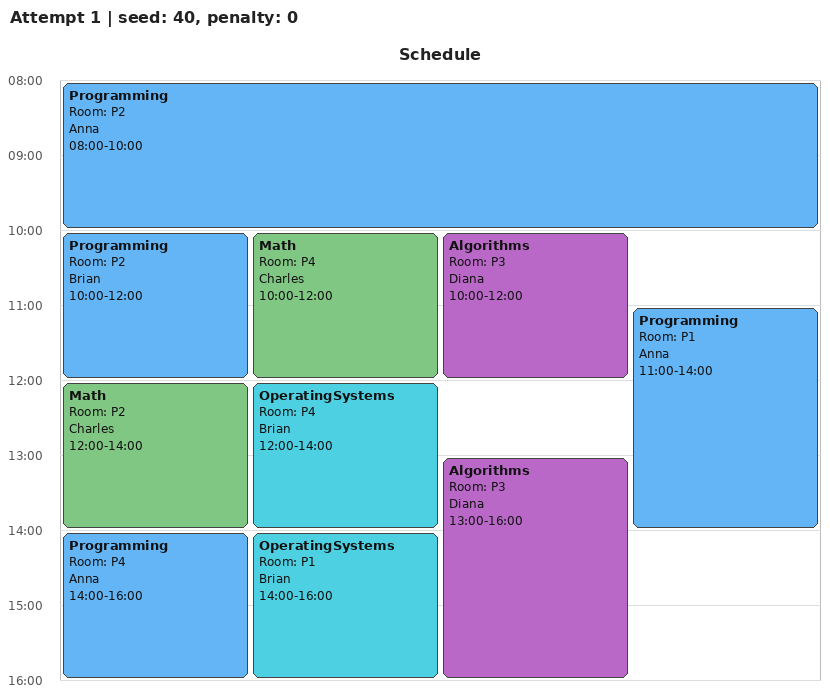

In [109]:
# ---------- PyGAD ----------
def crossover_func(parents, offspring_size, ga_instance):
  """Uniform crossover on whole lectures: a [room, teacher, start] triple always stays together."""
  offspring = []
  for k in range(offspring_size[0]):
    p1, p2 = parents[k % len(parents)], parents[(k + 1) % len(parents)]
    from_p1 = np.repeat(np.random.rand(N) < 0.5, 3)
    offspring.append(np.where(from_p1, p1, p2))
  return np.array(offspring)
# ---------- run (restart with a new random seed until a valid schedule is found) ----------
attempts = []
for attempt in range(1, 11):
  seed = random.randint(0, 100)
  ga = pygad.GA(
    num_generations=500,
    num_parents_mating=20,
    sol_per_pop=100,
    num_genes=3 * N,
    gene_type=int,
    gene_space=gene_space,
    fitness_func=fitness_func,
    parent_selection_type="tournament",
    K_tournament=4,
    keep_elitism=5,
    crossover_type=crossover_func,
    mutation_type="random",
    mutation_num_genes=3,
    stop_criteria=["reach_1.0"],
    random_seed=seed,
  )
  ga.run()
  solution, fit, _ = ga.best_solution()
  attempts.append((attempt, seed, solution))
  print(f"attempt {attempt}| seed: {seed}, generations: {ga.generations_completed}, penalty: {penalty(solution)}")
  if penalty(solution) == 0:
    break

show_attempts(attempts)

## Task 2

### Greedy algorithm for initial population generation
```
1. sort class by longest first
2. check for valid placement
3. if there are no valid placements, choose the placement with the lowest penalty
4. check for valid teacher and room combination
5. if there are no valid combinations, choose the combination with the lowest penalty
```

The logic behind longest class first is that if we try to fit a long class into a packed schedule there will be more overlaps.

### Custom crossover function

If we look back at our gene structure: $[c_0,\ t_0,\ s_0,\ c_1,\ t_1,\ s_1,\ \dots,\ c_{n-1},\ t_{n-1},\ s_{n-1}]$, each class is defined by three parametres so it makes sense that the child inherits all of them from the same parent.  
  
The function will chose witch classes are inherited from which parent.

### Custom mutation function

The idea is to prioritize mutation of invalid classes (lectures).  
```
1. identify invalid classes
2. randomly choose one to mutate
3. calculate witch class part generates the lowest penalty upon changing
4. if the lowest penalty value between class parts is less than 2 chose a random one
5. replace the chosen class with the generated one
```

Note that class parts are the teacher, the room, the start time.


In [110]:
import matplotlib.pyplot as plt
import time

Random seed: 98


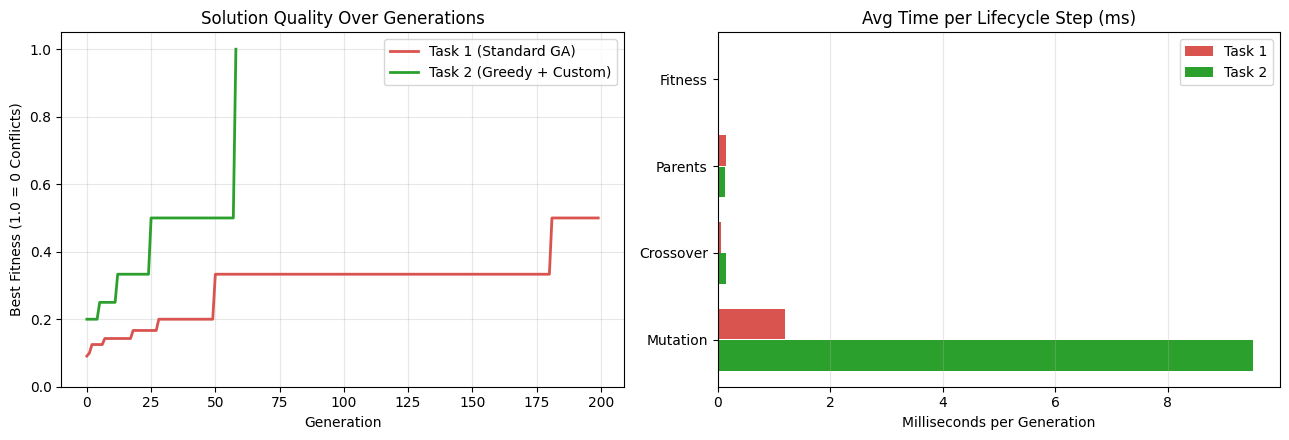

Task 1: 200 gens | Final Penalty: 1
Task 2: 59 gens | Final Penalty: 0 (Init took 38.7 ms)


In [134]:
def generate_greedy_population(pop_size, seed):
  rng = random.Random(seed)
  pop = np.zeros((pop_size, 3 * N), dtype=int)

  for i in range(pop_size):
    order = list(range(N))
    rng.shuffle(order)
    order.sort(key=lambda k: lec_dur[k], reverse=True)

    sol = np.array([rng.choice(gene_space[g]) for g in range(3 * N)])
    for k in order:
      best_pen, best_choice = float("inf"), None
      # Sample up to 6 random (room, teacher, start) placements per lecture
      for _ in range(6):
        r = rng.choice(gene_space[3 * k])
        t = rng.choice(gene_space[3 * k + 1])
        s = rng.choice(gene_space[3 * k + 2])
        sol[3 * k : 3 * k + 3] = [r, t, s]
        p = penalty(sol)
        if p < best_pen:
          best_pen, best_choice = p, (r, t, s)
      sol[3 * k : 3 * k + 3] = best_choice
    pop[i] = sol

  return pop


# ---------- 2. Custom Crossover & Mutation ----------
def block_crossover(parents, offspring_size, ga_instance):
  """Swaps complete [room, teacher, start] class blocks between parents."""
  offspring = np.empty(offspring_size, dtype=int)
  for i in range(offspring_size[0]):
    p1 = parents[i % len(parents)].reshape(N, 3)
    p2 = parents[(i + 1) % len(parents)].reshape(N, 3)
    mask = np.random.rand(N, 1) < 0.5
    offspring[i] = np.where(mask, p1, p2).flatten()
  return offspring


def targeted_mutation(offspring, ga_instance):
  """Repairs conflicting lectures and applies random mutation."""

  rng = ga_instance.numpy_random_generator
  RANDOM_MUTATION_PROB = 0.10

  for i in range(offspring.shape[0]):
    sol = offspring[i]

    invalid = [k for k, r in enumerate(violation_reasons(sol)) if r]

    if invalid:
      k = int(rng.choice(invalid))
      best_pen, best_gene = penalty(sol), sol.copy()

      # Targeted mutation: test single-attribute fixes
      for part in range(3):
        gene_idx = 3 * k + part
        orig = sol[gene_idx]

        for val in gene_space[gene_idx]:
          sol[gene_idx] = val
          p = penalty(sol)

          if p < best_pen:
            best_pen, best_gene = p, sol.copy()

        sol[gene_idx] = orig

      offspring[i] = best_gene

    # Random mutation: maintain genetic diversity
    for gene_idx in range(3 * N):
      if rng.random() < RANDOM_MUTATION_PROB:
        current = offspring[i, gene_idx]

        alternatives = [
          val for val in gene_space[gene_idx]
          if val != current
        ]

        if alternatives:
          offspring[i, gene_idx] = rng.choice(alternatives)

  return offspring


class Profiler:
  def __init__(self):
    self.times = {k: [] for k in ["fitness", "parents", "crossover", "mutation"]}
    self.fitness = []
    self.t = 0.0

  def _tick(self, key=None):
    now = time.perf_counter()
    if key:
      self.times[key].append((now - self.t) * 1000)
    self.t = now

  def run(self, ga):
    ga.on_start = lambda ga_instance: self._tick()

    ga.on_fitness = lambda ga_instance, *args: self._tick("fitness")
    ga.on_parents = lambda ga_instance, *args: self._tick("parents")
    ga.on_crossover = lambda ga_instance, *args: self._tick("crossover")
    ga.on_mutation = lambda ga_instance, *args: self._tick("mutation")

    ga.on_generation = self._on_gen

    ga.run()
    return self

  def _on_gen(self, ga):
    best = float(np.max(ga.last_generation_fitness))
    self.fitness.append(best)
    self._tick()

    if best == 1.0:
      return "stop"
    
seed = random.randint(0, 100)
print(f"Random seed: {seed}")

base_cfg = dict(
  num_generations=200, sol_per_pop=40, num_parents_mating=20,
  fitness_func=fitness_func, num_genes=3 * N, gene_space=gene_space,
  gene_type=int, keep_elitism=2, random_seed=seed
)

p1 = Profiler().run(pygad.GA(crossover_type="single_point", mutation_type="random", mutation_percent_genes=10, **base_cfg))

t0 = time.perf_counter()

G_POP_SIZE = base_cfg["sol_per_pop"]

greedy_pop = generate_greedy_population(G_POP_SIZE, seed)
init_ms = (time.perf_counter() - t0) * 1000

p2 = Profiler().run(pygad.GA(initial_population=greedy_pop, crossover_type=block_crossover, mutation_type=targeted_mutation, **base_cfg))

# --- Plotting ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# Graph 1: Convergence speed (Fitness & Penalty side-by-side intuition)
ax1.plot(p1.fitness, label="Task 1 (Standard GA)", color="#d9534f", lw=2)
ax1.plot(p2.fitness, label="Task 2 (Greedy + Custom)", color="#2ca02c", lw=2)
ax1.set(title="Solution Quality Over Generations", xlabel="Generation",
        ylabel="Best Fitness (1.0 = 0 Conflicts)", ylim=(0, 1.05))
ax1.grid(alpha=0.3)
ax1.legend()

# Graph 2: Horizontal bar chart of step times (easier to read labels & values)
steps = ["Fitness", "Parents", "Crossover", "Mutation"]
y = np.arange(len(steps))
t1_ms = [np.mean(p1.times[s.lower()]) for s in steps]
t2_ms = [np.mean(p2.times[s.lower()]) for s in steps]

ax2.barh(y - 0.18, t1_ms, height=0.35, label="Task 1", color="#d9534f")
ax2.barh(y + 0.18, t2_ms, height=0.35, label="Task 2", color="#2ca02c")
ax2.set(title="Avg Time per Lifecycle Step (ms)", xlabel="Milliseconds per Generation", yticks=y, yticklabels=steps)
ax2.invert_yaxis()
ax2.grid(axis="x", alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

print(f"Task 1: {len(p1.fitness)} gens | Final Penalty: {(1/p1.fitness[-1])-1:.0f}")
print(f"Task 2: {len(p2.fitness)} gens | Final Penalty: {(1/p2.fitness[-1])-1:.0f} (Init took {init_ms:.1f} ms)")

## Task 3

The idea is to reduce the penatly for less than it increases if wrong, but just enought so that it will be seen and carried throught new generations. 

### Prefrences
The penalty is reduced if the teacher prefrence is satisfied.

### Balance
The penalty is reduced if teaching hours are more balanced. 
Goal is to prioritize chosing the teacher with the lowest sum of teaching hours, which will lead to a more balanced schedule.   
The idea here is to also check if maybe chosing a teacher will be benefical to balancing, despite it being a invalid choice.


In [98]:
import json
def read_preferences(path):
  dc = {}
  with open(path, "r", encoding="utf-8") as f:
    for line in f:
      line = line.strip()
      if not line:
        continue

      # Split at the first '{' to separate the teacher's name from the JSON-like dictionary
      key, raw_data = line.split("{", 1)

      # Re-attach '{' and replace curly/smart quotes with standard double quotes for valid JSON
      clean_json = ("{" + raw_data).replace("“", '"').replace("”", '"')

      dc[key.strip()] = json.loads(clean_json)
  return dc
preferences = read_preferences("Preferences.txt")

## Task 4

### LLM logs
Includes links to chat logs:
- Task1 | Claude used for writing code based on ideas and simpler functions: 
    - https://claude.ai/share/6fb8eeb7-75c9-4016-bc15-8e21c2d924ff
    - For better display functions we only pasted code from a different LLM, but couldn't find the link
    - also used this as a prompt to generate a better prompt after discovering that we read the instructions wrong:
    <i>can you write me a prompt that you would be able to use to correctly modify the code so it works, along the lines it seems i have read wrong and we only need a one day schedule...</i>

- Task 2 | Code generations based on ideas for functions:
  - https://share.gemini.google/wxpNhhAFnOF0
- Task 2 | Debugging and recommendations:
  - https://chatgpt.com/share/6b06c54e-5d90-83ed-b55d-e0edbe335f18

- Task 3 | Prefrence reading function:
  - https://share.gemini.google/sJgJwClbAc5E

- Task 3 | Code implementation of ideas:
  - https://share.gemini.google/HTZfyEQ5oiX9